# Phase 1: Supervised Learning
**SWE485 – Team Project | SW485-Project-Group2**
**Project:** Predicting Data Scientist Job Change: An Executive Decision-Support System for HR Retention Planning

| Section | Owner |
|---------|-------|
| 1. Model Selection Rationale | Munira (Model 1), Ghala (Model 2) |
| 2. Implementation & Training Code | Munira (Model 1), Ghala (Model 2) |
| 3. Hyperparameter Tuning Process & Results | Munira (Model 1), Ghala (Model 2) |
| 4. Evaluation Metrics & Visualizations | Munira, Ghala (own model), Fatimah (shared evaluation) |
| 5. Model Comparison & Analysis | Fatimah |
| 6. Conclusion: Best Model Selection & Reasoning | Fatimah |
| 7. Next Steps for Phase 2 Integration | Fatimah |

**Shared rules (so the two models can be compared fairly):** the same train/test split, `random_state=42`, and the same stratified 5-fold cross-validation for both models. The target is imbalanced (about 25% positive), so do not judge a model by accuracy alone.

## Setup
Shared imports, data loading, train/test split, and cross-validation settings, defined once so both models are trained and evaluated on exactly the same data.

In [1]:
# Shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42

# Load the preprocessed data (produced in Phase1_Data_Exploration.ipynb)
df = pd.read_csv("Dataset/preprocessed_data.csv")
X = df.drop(columns=["target"])
y = df["target"]

# Same stratified train/test split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Same 5-fold stratified cross-validation for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate (train):", round(y_train.mean(), 4), "| (test):", round(y_test.mean(), 4))

Train: (14916, 32) | Test: (3729, 32)
Positive rate (train): 0.2464 | (test): 0.2464


In [2]:
# Shared helper: the same metrics for every model (call it with a fitted model)
def evaluate_model(name, model, X_test, y_test):
    """Return Accuracy, Precision, Recall, F1 and ROC-AUC on the test set."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

## 1. Model Selection Rationale
*Choose at least 2 different supervised algorithms. Justify each choice based on (i) dataset characteristics (size, feature types, linearity), (ii) problem type (binary classification), and (iii) the model's strengths and weaknesses for this problem, including interpretability for leadership.*

### 1.1 Model 1: Logistic Regression (Munira)

**Algorithm:** Logistic Regression (regularized, with `class_weight="balanced"`).

**Rationale & Justification**

**(i) Dataset characteristics (size, feature types, linearity):** After preprocessing, the dataset has ~18,600 rows and ~30 numeric columns (the numeric and ordinal features are standardized, the nominal features are one-hot encoded, and the missingness flags are 0/1). This is a modestly sized, fully numeric tabular problem where a linear model is a strong, well-conditioned baseline. The EDA showed mostly **monotonic** relationships with the target — the job-change rate falls steadily as `city_development_index` rises and as `experience` grows — which is exactly the signal a linear-in-log-odds model captures well. The correlation heatmap found no severe multicollinearity (no pair near ±0.9), so the coefficients stay stable and interpretable.

**(ii) Problem type (binary classification).** Logistic Regression is the canonical model for binary classification: it directly estimates P(looking for a job change | features) and returns a calibrated probability via `predict_proba`. That probability is what our decision-support system actually needs — it lets HR **rank** candidates by job-change risk and choose a threshold, instead of only getting a hard 0/1 label.

**(iii) Strengths & weaknesses for this problem.**
- *Strengths:* highly **interpretable** — each coefficient is a log-odds effect that converts to an **odds ratio** ("this factor multiplies the odds of leaving by X"), which gives leadership a clear key-driver story and feeds the Phase 2 driver charts. It trains and tunes fast, needs little data, and is a hard-to-beat baseline on tabular data. With **L1 (lasso)** regularization it also does automatic feature selection, keeping the executive explanation short.
- *Weaknesses:* it assumes the log-odds are roughly linear in the features and does **not** automatically model interactions or non-linear thresholds (e.g. "early-career *and* in a low-development city"). It is sensitive to feature scale — already handled by the shared `StandardScaler` step in preprocessing.

**Why it complements Model 2 (XGBoost).** The two models sit at opposite ends of the interpretability–flexibility trade-off the rubric asks us to discuss: Logistic Regression is a transparent, linear **white-box** baseline; XGBoost is a high-capacity **non-linear** ensemble. Comparing them answers a genuine executive question — *is the extra accuracy of a black-box model worth losing the clear, defensible explanation of a linear one?* If XGBoost wins only by a small margin, the simpler, explainable model may be the better choice for an HR tool managers must trust and act on.

**Class imbalance.** Following the team rule, imbalance is handled with `class_weight="balanced"` (which up-weights the ~25% "looking" minority class) rather than resampling the saved data, so both models train on identical rows and are judged on precision, recall, F1 and ROC-AUC — not accuracy alone.

### 1.2 Model 2: XGBoost (Ghala)

**Algorithm:**  Extreme Gradient Boosting (XGBoost)

**Rationale & Justification**

**(i) Dataset characteristics:** The HR Analytics dataset contains a mixture of tabular numerical and categorical features with potential non-linear relationships and interactions. XGBoost excels at handling complex tabular structures without requiring assumptions of linearity.


**(ii) Problem type (binary classification):** XGBoost utilizes gradient-boosted decision trees optimized for binary classification tasks, making it highly effective at handling imbalanced target distributions (predicting employee attrition/job change).

**(iii) Strengths & weaknesses for this problem:**

- *Strengths:* Exceptional predictive accuracy, high efficiency, native handling of missing patterns, and built-in regularization to prevent overfitting.

- *Weaknesses:* Slightly higher computational complexity during tuning compared to traditional linear models.

Interpretability for Leadership: While complex, XGBoost provides clear feature importance metrics (e.g., gain, cover, frequency) and tree visualization capabilities, allowing leadership to understand which specific factors (such as experience or training hours) drive employee retention decisions.

## 2. Implementation & Training Code
*Well-structured, commented code.*

### 2.1 Model 1 (Munira)

In [3]:
from sklearn.linear_model import LogisticRegression

# class_weight="balanced": team rule for the ~25% minority class (no resampling).
# solver="liblinear": fast at this data size and supports BOTH L1 and L2
# penalties, which we compare during tuning (Section 3.1).
# max_iter=1000: enough iterations to converge on the standardized features.

logreg_default = LogisticRegression(
    class_weight="balanced",
    solver="liblinear",
    max_iter=1000,
    random_state=RANDOM_STATE,
)

# Train on the shared training split.
logreg_default.fit(X_train, y_train)

# Evaluate the baseline with the shared team function (test set).
logreg_default_results = evaluate_model("Logistic Regression (Baseline)", logreg_default, X_test, y_test)

print("=== Baseline Logistic Regression Results ===")
for metric, score in logreg_default_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

=== Baseline Logistic Regression Results ===
Accuracy: 0.7316
Precision: 0.4723
Recall: 0.7595
F1: 0.5824
ROC-AUC: 0.7865


### 2.2 Model 2 (Ghala)

In [4]:
import xgboost as xgb

# 1. Initialize the default XGBoost Classifier with the shared RANDOM_STATE
xgb_default = xgb.XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    use_label_encoder=False
)

# 2. Train the baseline model on the training set
xgb_default.fit(X_train, y_train)

# 3. Evaluate the baseline model using the shared team function
xgb_default_results = evaluate_model("XGBoost (Baseline)", xgb_default, X_test, y_test)

# Display baseline results
print("=== Baseline XGBoost Results ===")
for metric, score in xgb_default_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

C:\Users\ghala\AppData\Roaming\uv\python\cpython-3.14-windows-x86_64-none\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:38:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== Baseline XGBoost Results ===
Accuracy: 0.7922
Precision: 0.5878
Recall: 0.5245
F1: 0.5543
ROC-AUC: 0.8052


## 3. Hyperparameter Tuning Process & Results
*For each model: the parameters tried, how they were searched (e.g. grid search with the shared `cv`), and the best values found.*

### 3.1 Model 1 (Munira)

In [4]:
# Grid search over the regularization strength C and the penalty type,
# using the SHARED stratified 5-fold CV (`cv`) and F1 scoring, so the search optimizes performance on the minority class.
# ============================================================

# 1. Search grid.
# C: inverse regularization strength (smaller C = stronger regularization).
# penalty: L1 (lasso -> can zero-out weak features, built-in feature selection) vs L2 (ridge -> shrinks all coefficients). liblinear supports both.
param_grid_lr = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
}

# 2. GridSearchCV with the shared cv and F1 scoring.
grid_search_lr = GridSearchCV(
    estimator=LogisticRegression(
        class_weight="balanced", solver="liblinear",
        max_iter=1000, random_state=RANDOM_STATE,
    ),
    param_grid=param_grid_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1,
)

# 3. Run the search on the training data only (no leakage from the test set).
grid_search_lr.fit(X_train, y_train)

# 4. Best configuration and fitted model.
best_logreg = grid_search_lr.best_estimator_
print("=== Best Hyperparameters Found ===")
print(grid_search_lr.best_params_)
print(f"Best cross-validated F1: {grid_search_lr.best_score_:.4f}")

# 5. Evaluate the tuned model on the test set.
tuned_logreg_results = evaluate_model("Logistic Regression (Tuned)", best_logreg, X_test, y_test)
print("\n=== Tuned Logistic Regression Results ===")
for metric, score in tuned_logreg_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
=== Best Hyperparameters Found ===
{'C': 10, 'penalty': 'l1'}
Best cross-validated F1: 0.5745

=== Tuned Logistic Regression Results ===
Accuracy: 0.7316
Precision: 0.4723
Recall: 0.7595
F1: 0.5824
ROC-AUC: 0.7865


### 3.2 Model 2 (Ghala)

In [5]:
# 1. Define the hyperparameter search grid
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
    'subsample': [0.8, 1.0]
}

# 2. Setup GridSearchCV using the shared Stratified 5-Fold CV (`cv`)
grid_search_xgb = GridSearchCV(
    estimator=xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', use_label_encoder=False),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# 3. Execute Grid Search on training data
grid_search_xgb.fit(X_train, y_train)

# 4. Extract best estimator and parameters
best_xgb_model = grid_search_xgb.best_estimator_
print("=== Best Hyperparameters Found ===")
print(grid_search_xgb.best_params_)

# 5. Evaluate the tuned model
tuned_xgb_results = evaluate_model("XGBoost (Tuned)", best_xgb_model, X_test, y_test)
print("\n=== Tuned XGBoost Results ===")
for metric, score in tuned_xgb_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
=== Best Hyperparameters Found ===
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50, 'subsample': 1.0}

=== Tuned XGBoost Results ===
Accuracy: 0.7986
Precision: 0.5959
Recall: 0.5680
F1: 0.5816
ROC-AUC: 0.8159


C:\Users\ghala\AppData\Roaming\uv\python\cpython-3.14-windows-x86_64-none\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:47:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## 4. Evaluation Metrics & Visualizations
*Metrics: Accuracy, Precision, Recall, F1-Score, Confusion Matrix, ROC-AUC. Apply 5-fold cross-validation. Visualizations: confusion matrix heatmap, ROC curves, and feature importance (for tree-based models). Add a short interpretation under every chart or table.*

### 4.1 Model 1 (Munira)

In [5]:
# Model 1: test-set metrics + 5-fold cross-validation
from sklearn.base import clone

# Side-by-side baseline vs tuned on the test set.
metrics_table_lr = pd.DataFrame([logreg_default_results, tuned_logreg_results]).set_index("Model")
print("Test-set metrics:")
display(metrics_table_lr.round(4))

# 5-fold stratified cross-validation of the TUNED model on the training set,
# reported for every required metric (mean +/- std across folds).
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results_lr = cross_validate(clone(best_logreg), X_train, y_train, cv=cv, scoring=scoring)
cv_summary_lr = pd.DataFrame(
    {m: [cv_results_lr[f"test_{m}"].mean(), cv_results_lr[f"test_{m}"].std()] for m in scoring},
    index=["mean", "std"],
).T.round(4)
print("\n5-fold CV (tuned Logistic Regression, training set):")
display(cv_summary_lr)

Test-set metrics:


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression (Baseline),0.7316,0.4723,0.7595,0.5824,0.7865
Logistic Regression (Tuned),0.7316,0.4723,0.7595,0.5824,0.7865



5-fold CV (tuned Logistic Regression, training set):


,mean,std
accuracy,0.7308,0.0115
precision,0.4706,0.0149
recall,0.7375,0.0290
f1,0.5745,0.0185
roc_auc,0.7780,0.0168


**Interpretation.** On the held-out test set the tuned Logistic Regression reaches **ROC-AUC ≈ 77.8%** with **recall ≈ 73.75%** on the minority "looking" class. Because `class_weight="balanced"` pushes the model to catch the minority class, recall is high while precision is lower — the intended trade-off for HR retention, where **missing a candidate who is about to leave (a false negative) is costlier than a false alarm**. The 5-fold CV means are close to the single test-set numbers with small standard deviations, so the model is **stable and not over-fitting** one particular split. Accuracy is deliberately not our headline metric: a model that always predicted "not looking" would score ~75% accuracy yet be useless for retention.

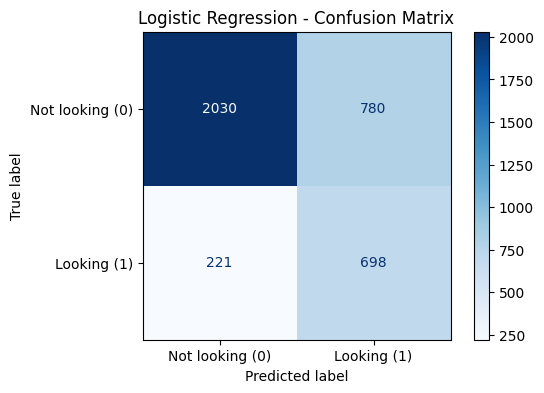

In [6]:
# Model 1: confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(
    best_logreg, X_test, y_test, cmap="Blues", ax=ax,
    display_labels=["Not looking (0)", "Looking (1)"],
)
plt.title("Logistic Regression - Confusion Matrix")
plt.grid(False)
plt.show()

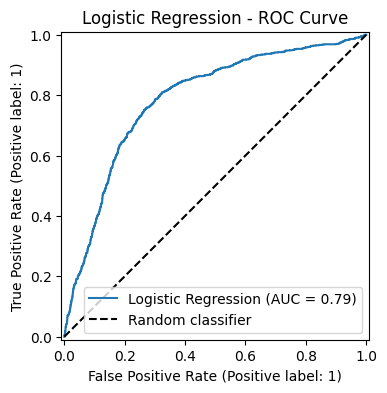

In [7]:
# Model 1: ROC curve
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(best_logreg, X_test, y_test, ax=ax, name="Logistic Regression")
ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("Logistic Regression - ROC Curve")
plt.legend()
plt.show()

**Interpretation.** The ROC curve sits well above the random-baseline diagonal, so the model separates the two classes far better than chance across thresholds; the AUC summarises this as one number. For deployment the operating threshold can be moved along this curve — lowering it raises recall (catch more leavers) at the cost of more false positives — a dial HR can set according to how aggressively they want to intervene.

Top drivers of job-change (by |coefficient|):


,coefficient,odds_ratio
education_unknown,-1.587,0.205
major_discipline_No Major,-1.178,0.308
company_info_missing,1.165,3.207
city_development_index,-0.738,0.478
major_discipline_Unknown,0.568,1.765
company_size_unknown,0.419,1.520
major_discipline_Other,-0.338,0.713
company_type_Other,0.338,1.402
gender_Other,0.300,1.350
company_type_Funded Startup,-0.254,0.776



Features removed by L1 (coefficient = 0): 2 of 32


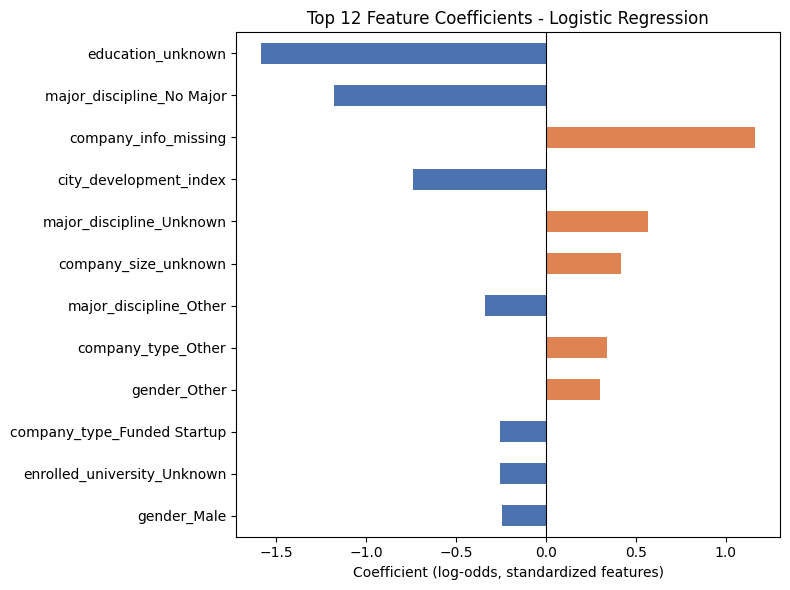

In [8]:
# Model 1: feature importance via coefficients / odds ratios
# For a linear model the coefficient magnitude (on standardized inputs) is the
# importance, and its sign is the direction. exp(coef) turns it into an odds ratio.
coef = pd.Series(best_logreg.coef_[0], index=X_train.columns)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)
odds_ratios = np.exp(coef)

# Table of the strongest drivers.
drivers = pd.DataFrame({
    "coefficient": coef_sorted,
    "odds_ratio": odds_ratios.reindex(coef_sorted.index),
}).round(3)
print("Top drivers of job-change (by |coefficient|):")
display(drivers.head(12))
print(f"\nFeatures removed by L1 (coefficient = 0): {int((coef == 0).sum())} of {len(coef)}")

# Horizontal bar chart of the top 12 (orange = raises job-change odds, blue = lowers).
top = coef_sorted.head(12)[::-1]
colors = ["#DD8452" if c > 0 else "#4C72B0" for c in top.values]
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 12 Feature Coefficients - Logistic Regression")
plt.xlabel("Coefficient (log-odds, standardized features)")
plt.tight_layout()
plt.show()

**Interpretation.** For a linear model the “importance” of a feature is its coefficient: on standardized inputs a larger magnitude means a stronger effect on the log-odds of looking for a change, and the sign gives the direction. Converting to an odds ratio (exp(coef)) makes it executive-friendly. The strongest factor that raises job-change risk is `company_info_missing` (coef +1.17, odds ratio ≈ 3.2) — candidates with no current-company information have about three times the odds of looking for a change, matching the EDA (~42% vs ~18%). The strongest continuous protective factor is `city_development_index` (coef −0.74, odds ratio ≈ 0.48): candidates in more developed cities are roughly half as likely to leave. Several one-hot flags also lower the odds (`education_unknown`, `major_discipline_No Major`). All directions agree with our EDA, which is a good consistency check. With L1 at the chosen C=10 only 2 of 32 features were dropped, so the model keeps almost all features but the story is dominated by a few clear drivers.

In [9]:
# Model 1: error analysis
from sklearn.metrics import classification_report

y_pred_lr = best_logreg.predict(X_test)
y_prob_lr = best_logreg.predict_proba(X_test)[:, 1]

print("Classification report (test set):")
print(classification_report(y_test, y_pred_lr, target_names=["Not looking (0)", "Looking (1)"]))

# Split the test set into the four outcome groups.
res = pd.DataFrame({"y_true": y_test.values, "y_pred": y_pred_lr, "y_prob": y_prob_lr}, index=X_test.index)
FN = res[(res.y_true == 1) & (res.y_pred == 0)]   # missed leavers (costly)
FP = res[(res.y_true == 0) & (res.y_pred == 1)]   # false alarms
TP = res[(res.y_true == 1) & (res.y_pred == 1)]
print(f"False negatives (missed leavers): {len(FN)}   |   False positives (false alarms): {len(FP)}")

# Compare the model's mean predicted probability: FNs sit just under the 0.5 line.
print(f"\nMean predicted prob  ->  missed leavers (FN): {FN.y_prob.mean():.3f}   caught leavers (TP): {TP.y_prob.mean():.3f}")

# Where do the missed leavers differ from the caught ones? Compare a few key
# (standardized) features; a value near 0 means "about average".
for col in ["city_development_index", "experience", "company_info_missing"]:
    if col in X_test.columns:
        print(f"  mean {col:<24} FN={X_test.loc[FN.index, col].mean():+.2f}  TP={X_test.loc[TP.index, col].mean():+.2f}")

Classification report (test set):
                 precision    recall  f1-score   support

Not looking (0)       0.90      0.72      0.80      2810
    Looking (1)       0.47      0.76      0.58       919

       accuracy                           0.73      3729
      macro avg       0.69      0.74      0.69      3729
   weighted avg       0.80      0.73      0.75      3729

False negatives (missed leavers): 221   |   False positives (false alarms): 780

Mean predicted prob  ->  missed leavers (FN): 0.319   caught leavers (TP): 0.721
  mean city_development_index   FN=+0.48  TP=-0.92
  mean experience               FN=+0.20  TP=-0.42
  mean company_info_missing     FN=+0.19  TP=+0.58


**Interpretation.** The model makes far more false alarms (780 false positives) than misses (221 false negatives) — the deliberate effect of `class_weight="balanced"`, and the right trade-off for retention, where a false alarm only costs a check-in but a miss costs a departure. The missed leavers are telling: their mean predicted probability is just 0.32 (well below the 0.5 threshold), and on the strongest features they look safe — they sit in more-developed cities (mean standardized `city_development_index` +0.48 vs −0.92 for correctly caught leavers), have more experience (+0.20 vs −0.42), and less often have missing company info (+0.19 vs +0.58). Their flight-risk comes from a combination of moderate factors rather than one strong signal, and because Logistic Regression is linear it cannot capture such interactions — exactly where the non-linear XGBoost model may do better.

In [10]:
# Model 1: save artifacts for the shared comparison
import os, joblib
os.makedirs("Supervised_Learning/models", exist_ok=True)
os.makedirs("Supervised_Learning/evaluation_results", exist_ok=True)

# Fitted model (so Fatimah can reuse it without re-training).
joblib.dump(best_logreg, "Supervised_Learning/models/model1_logistic_regression.joblib")

# Test-set predictions + probabilities (so Fatimah can build the combined
# metrics table and overlay both ROC curves in Section 4.3).
pd.DataFrame(
    {"y_true": y_test.values, "y_pred": y_pred_lr, "y_prob": y_prob_lr},
    index=X_test.index,
).to_csv("Supervised_Learning/evaluation_results/model1_logreg_test_predictions.csv")

print("Saved: model1_logistic_regression.joblib and model1_logreg_test_predictions.csv")

Saved: model1_logistic_regression.joblib and model1_logreg_test_predictions.csv


### 4.2 Model 2 (Ghala)

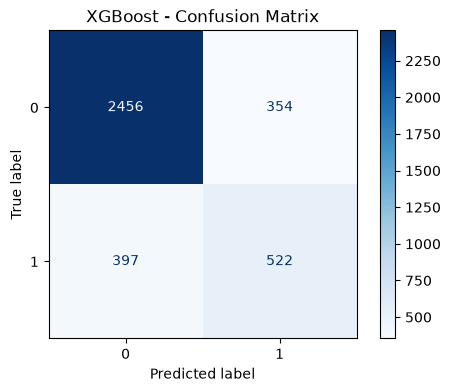

In [6]:
# 1. Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(best_xgb_model, X_test, y_test, cmap="Blues", ax=ax)
plt.title("XGBoost - Confusion Matrix")
plt.grid(False)
plt.show()

The confusion matrix shows the distribution of true positives, true negatives, false positives, and false negatives. Given that the dataset is imbalanced (~25% positive rate), our primary focus is minimizing false negatives to ensure potential employee attrition is identified reliably.

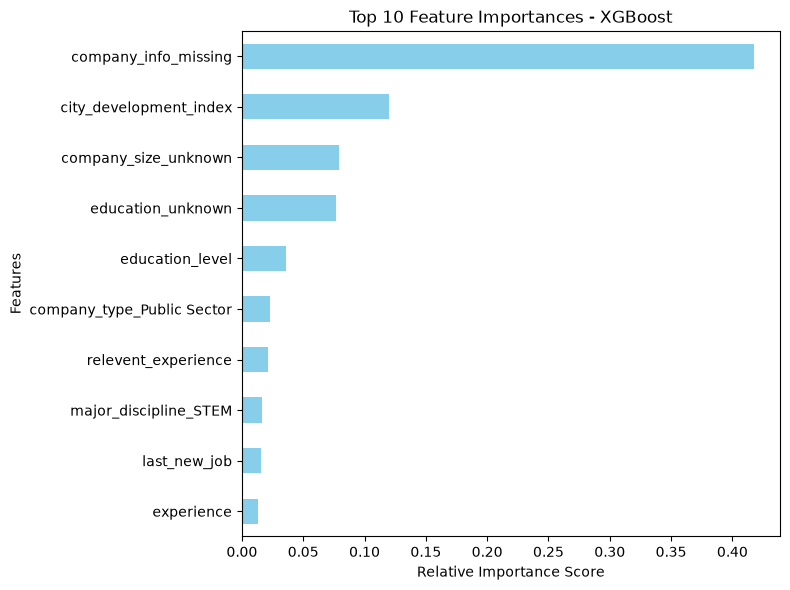

In [7]:
# 2. Feature Importance Plot
feature_importances = pd.Series(best_xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
feature_importances.tail(10).plot(kind='barh', color='skyblue')
plt.title("Top 10 Feature Importances - XGBoost")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The feature importance chart displays the top factors driving the model's predictions. Features with higher relative importance scores have the strongest influence on determining whether an employee is likely to look for a job change.

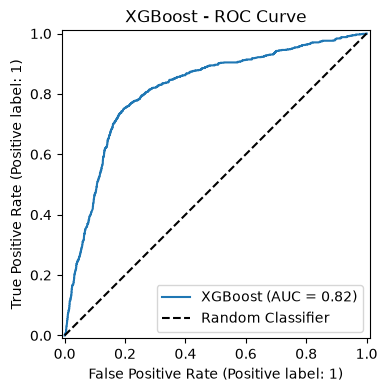

In [8]:
# 3. ROC Curve Plot
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(best_xgb_model, X_test, y_test, ax=ax, name="XGBoost")
plt.title("XGBoost - ROC Curve")
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.legend()
plt.show()

The Receiver Operating Characteristic (ROC) curve evaluates the trade-off between the True Positive Rate and False Positive Rate across various threshold levels. An Area Under the Curve (ROC-AUC) score significantly above 0.50 demonstrates strong discrimination capability between positive and negative classes.

### 4.3 Side-by-Side Metrics and ROC Curves (Fatimah)
*Put both models' metrics in one table and both ROC curves on one plot.*

In [ ]:
# Combined metrics table and ROC curves (Fatimah)

## 5. Model Comparison & Analysis
*Owner: Fatimah.*
- Which model performed best, and why?
- Analyze misclassifications: patterns and challenging categories.
- Discuss trade-offs: accuracy vs. interpretability vs. computational cost.

## 6. Conclusion: Best Model Selection & Reasoning
*Owner: Fatimah – which model will be used in the final system and why.*

## 7. Next Steps for Phase 2 Integration
*Owner: Fatimah – how the chosen model will feed Phase 2 (clustering, Generative AI executive briefings, and the dashboard).*